# Semaine 1 — Épisode 1 : Le protocole Modbus

Navigation : [🏠 Sommaire principal (introduction.ipynb)](../introduction.ipynb) > **Semaine 1 : Les bases de l'IoT** > **Épisode 1 : Modbus**

> **Objectifs de cet épisode :**
> 1. Comprendre l'architecture et les principes de fonctionnement de **Modbus** (maître/esclave, bus série RS-485 et passerelles IP).
> 2. Maîtriser les **4 types de registres** (*Discrete Inputs*, *Coils*, *Input Registers*, *Holding Registers*) et leurs codes fonctions.
> 3. Construire et décoder des **trames Modbus RTU** en Python avec calcul de checksum **CRC-16**.
> 4. Interagir avec des équipements Modbus sur réseau IP via **passerelle TCP** et avec la bibliothèque **PyModbus**.
> 5. Pratiquer sur un cas concret et analyser les forces et faiblesses d'interopérabilité de Modbus pour l'IoT moderne.


## 1. Contexte : Modbus dans l'histoire des réseaux industriels

Apparu en **1979** (développé par l'entreprise Modicon, aujourd'hui Schneider Electric) pour connecter des automates programmables industriels (PLC), **Modbus** est le doyen des protocoles de communication encore activement utilisés aujourd'hui dans l'industrie, la gestion technique de bâtiment (GTB), et les systèmes SCADA.

À cette époque, le réseau Internet moderne n'existait pas encore dans l'industrie. Les équipements étaient reliés par des liaisons séries dédiées (notamment le bus différentiel **RS-485** ou des liaisons point-à-point **RS-232**).

> 💡 **Le fil conducteur de notre cours : l'analogie avec la télévision**
> Tout comme la télévision a commencé par des signaux analogiques diffusés sur des câbles coaxiaux dédiés avant de converger vers des paquets IP universels (streaming et vidéo à la demande sur Internet), le monde des objets industriels a commencé avec des bus de terrain spécialisés comme Modbus. Aujourd'hui, Modbus continue d'exister en se connectant à Internet via des **passerelles IP** (*gateways*) ou en encapsulant ses trames dans des paquets TCP/IP.


## 2. Les principes généraux de Modbus (Vidéo)

Regardez cette première vidéo extraite du MOOC qui présente le modèle d'échange et la structure fondamentale du protocole.


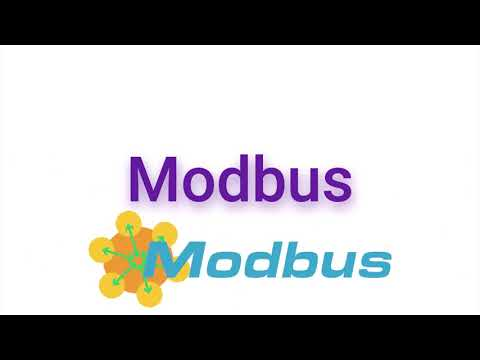

In [1]:
from IPython.display import YouTubeVideo
YouTubeVideo("Jj9Tmci7gXU", width=700, height=394)


## 3. Architecture et modèle de données

### 3.1. Topologie Primaire / Secondaires (Maître / Esclave)

Modbus repose sur un modèle d'échange strictement asymétrique de type **requête / réponse** :
- **Le Primaire** (*Master*) : il est unique sur le bus et a l'initiative de toutes les communications. Il n'a pas besoin d'adresse car tous les échanges se font avec lui.
- **Les Secondaires** (*Slaves*) : ils sont passifs et ne parlent que lorsqu'ils sont interrogés par le primaire.
  - Chaque secondaire possède une **adresse unique comprise entre 1 et 247**.
  - L'adresse `0` est réservée aux requêtes de diffusion (*broadcast*, écoute sans réponse).
  - Deux secondaires ne peuvent **jamais** communiquer directement entre eux.

![Architecture Modbus](images/Capture35.png)

---

### 3.2. Les 4 catégories de registres

Dans Modbus, toute information manipulée par un équipement est modélisée sous forme de **registres**. Il existe exactement 4 catégories, réparties selon deux critères : la **taille** (1 bit booléen ou 16 bits numérique) et les **droits d'accès** (Lecture seule ou Lecture / Écriture) :

| Catégorie de Registre | Type de donnée | Accès (côté Primaire) | Description & Exemples typiques |
| :--- | :---: | :---: | :--- |
| **Discrete Input** | 1 bit (Booléen) | **Lecture seule** (RO) | Entrée numérique physique : état d'un interrupteur, détecteur de fumée, fin de course. |
| **Coil** *(bobine)* | 1 bit (Booléen) | **Lecture & Écriture** (RW) | Sortie binaire commandable : allumer une LED, ouvrir/fermer un relais, activer une alarme. |
| **Input Register** | 16 bits (Mot / Word) | **Lecture seule** (RO) | Mesure physique analogique : température, hygrométrie, niveau d'un réservoir, pression. |
| **Holding Register** | 16 bits (Mot / Word) | **Lecture & Écriture** (RW) | Paramètre ou consigne modifiable : seuil d'alarme, vitesse de moteur, adresse esclave. |

![Catégories de registres Modbus](images/Capture36.png)

Un équipement Modbus peut comporter jusqu'à **10 000 registres** (de 0 à 9999 ou 1 à 10000 selon les conventions de numérotation) pour chacune de ces quatre familles.

---

### 3.3. Structure d'une trame Modbus RTU

Sur un bus série (ou encapsulé dans une liaison point-à-point), le format standard le plus courant est **Modbus RTU** (*Remote Terminal Unit*). La trame binaire est compacte et comprend 4 champs :

![Format de la trame Modbus](images/Capture37.png)

1. **Adresse de l'esclave (1 octet)** : `1` à `247` (identifie le destinataire en requête, et l'émetteur en réponse).
2. **Code de fonction (1 octet)** : indique l'opération demandée au secondaire.
3. **Données (taille variable)** :
   - En *lecture* : adresse du premier registre (2 octets) + nombre de registres à lire (2 octets).
   - En *réponse* : nombre d'octets de données + contenu des registres.
   - En *écriture* : adresse du registre (2 octets) + valeur à inscrire (2 octets ou plus).
4. **CRC-16 (2 octets, Little-Endian)** : somme de contrôle cyclique pour détecter d'éventuelles erreurs de transmission sur la ligne électrique.

#### Principaux codes de fonction standards :
- `0x01` (1) : **Read Coils** (Lecture de bobines 1-bit)
- `0x02` (2) : **Read Discrete Inputs** (Lecture d'entrées binaires)
- `0x03` (3) : **Read Holding Registers** (Lecture de registres de maintien 16-bits)
- `0x04` (4) : **Read Input Registers** (Lecture de registres d'entrée 16-bits)
- `0x05` (5) : **Write Single Coil** (Écriture d'une bobine 1-bit)
- `0x06` (6) : **Write Single Holding Register** (Écriture d'un registre de maintien 16-bits)
- `0x10` (16) : **Write Multiple Holding Registers** (Écriture d'un bloc de registres 16-bits)

> ⚠️ **Gestion des erreurs (Exceptions Modbus) :**
> Si le secondaire ne peut pas exécuter la requête (par exemple, si l'adresse de registre demandée n'existe pas), il renvoie une trame d'erreur dans laquelle le bit de poids fort du code fonction est mis à `1` (`Code fonction + 0x80`). L'octet suivant contient le code d'exception :
> - `0x01` : Fonction illégale (non supportée par l'appareil)
> - `0x02` : Adresse de données illégale (registre inexistant)
> - `0x03` : Valeur de donnée illégale
> - `0x04` : Défaillance de l'équipement esclave


## 4. Quiz 1 : Testez votre compréhension des principes Modbus

Répondez aux questions ci-dessous pour valider vos connaissances sur le modèle d'adressage et les catégories de registres.


In [2]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "✅ **Correct !**" if ok else "❌ **Pas tout à fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)

# Question 1: Adresse max
display(Markdown("### Question 1\n**Quelle est l'adresse maximale attribuable à un esclave Modbus RTU ?**"))
q1_w = widgets.Text(placeholder="Entrez un nombre", layout=widgets.Layout(width="250px"))
q1_b = widgets.Button(description="Vérifier", button_style="primary")
q1_o = widgets.Output()

def check_q1(_):
    q1_o.clear_output()
    with q1_o:
        ok = q1_w.value.strip() == "247"
        display(_feedback(ok, "Les adresses d'esclaves vont de 1 à 247 (1 octet, avec 0 réservé pour le broadcast et 248-255 réservés)."))
q1_b.on_click(check_q1)
display(widgets.HBox([q1_w, q1_b]), q1_o)

# Question 2: Capteur température
display(Markdown("### Question 2\n**Vous mesurez la température d'une pièce avec une sonde Modbus. De quel type est ce registre ?**"))
q2_w = widgets.RadioButtons(options=['Coil', 'Discrete Input', 'Input Register', 'Holding Register'], layout=widgets.Layout(width="350px"))
q2_b = widgets.Button(description="Vérifier", button_style="primary")
q2_o = widgets.Output()

def check_q2(_):
    q2_o.clear_output()
    with q2_o:
        ok = q2_w.value == 'Input Register'
        display(_feedback(ok, "La température est une grandeur analogique (16 bits) mesurée par le capteur, donc non modifiable par le primaire : c'est un **Input Register** (lecture seule)."))
q2_b.on_click(check_q2)
display(q2_w, q2_b, q2_o)

# Question 3: Commande relais
display(Markdown("### Question 3\n**Vous souhaitez piloter l'allumage/extinction (ON/OFF) d'un ventilateur via un contacteur. Quel type de registre utilisez-vous ?**"))
q3_w = widgets.RadioButtons(options=['Coil', 'Discrete Input', 'Input Register', 'Holding Register'], layout=widgets.Layout(width="350px"))
q3_b = widgets.Button(description="Vérifier", button_style="primary")
q3_o = widgets.Output()

def check_q3(_):
    q3_o.clear_output()
    with q3_o:
        ok = q3_w.value == 'Coil'
        display(_feedback(ok, "L'état d'un relais est binaire (1 bit) et doit pouvoir être lu et écrit (modifié) par le maître : c'est une bobine (**Coil**)."))
q3_b.on_click(check_q3)
display(q3_w, q3_b, q3_o)


### Question 1
**Quelle est l'adresse maximale attribuable à un esclave Modbus RTU ?**

Output()

### Question 2
**Vous mesurez la température d'une pièce avec une sonde Modbus. De quel type est ce registre ?**

RadioButtons(layout=Layout(width='350px'), options=('Coil', 'Discrete Input', 'Input Register', 'Holding Regis…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

### Question 3
**Vous souhaitez piloter l'allumage/extinction (ON/OFF) d'un ventilateur via un contacteur. Quel type de registre utilisez-vous ?**

RadioButtons(layout=Layout(width='350px'), options=('Coil', 'Discrete Input', 'Input Register', 'Holding Regis…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## 5. Pratique Python : Forger et décoder des trames Modbus RTU

Pour bien comprendre ce qui transite sur le fil électrique ou sur le socket réseau, implémentons nous-mêmes le calcul du **CRC-16** et la fabrication des trames binaires grâce au module standard `struct` de Python.

### Le calcul du CRC-16 Modbus
Le CRC-16 utilise le polynôme générateur inversé `0xA001` avec une valeur initiale de `0xFFFF`.
Le résultat de 16 bits est placé à la fin de la trame en **Little-Endian** (l'octet de poids faible en premier).


In [3]:
import struct

def crc16(data: bytes) -> int:
    """Calcule le CRC-16 standard Modbus.
    Si le CRC est recalculé sur l'ensemble [trame + son propre CRC], le résultat vaut 0 !
    """
    crc = 0xFFFF
    for byte in data:
        crc ^= byte
        for _ in range(8):
            crc = (crc >> 1) ^ 0xA001 if (crc & 1) else (crc >> 1)
    return crc

def build_modbus_rtu_request(slave_address: int, function_code: int, start_register: int, count: int) -> bytes:
    """Construit une trame de requête Modbus RTU avec son CRC."""
    # >BBHH = Big-Endian : 1 octet adresse, 1 octet fonction, 2 octets registre, 2 octets count
    payload = struct.pack(">BBHH", slave_address, function_code, start_register, count)
    # <H = Little-Endian : CRC16 sur 2 octets
    frame = payload + struct.pack("<H", crc16(payload))
    return frame

# Exemple : Interroger l'esclave 1, fonction 0x03 (Read Holding Registers), registre 0, 1 registre
test_frame = build_modbus_rtu_request(slave_address=1, function_code=0x03, start_register=0, count=1)
print(f"Trame RTU générée ({len(test_frame)} octets) :")
print(f"Hexadécimal : {test_frame.hex(' ').upper()}")
print(f"Octet par octet : {[f'0x{b:02X}' for b in test_frame]}")
print(f"Validation du CRC sur la trame complète : {crc16(test_frame)} (0 = CRC valide !)")


Trame RTU générée (8 octets) :
Hexadécimal : 01 03 00 00 00 01 84 0A
Octet par octet : ['0x01', '0x03', '0x00', '0x00', '0x00', '0x01', '0x84', '0x0A']
Validation du CRC sur la trame complète : 0 (0 = CRC valide !)


### Générateur interactif de trames Modbus
Testez différents codes de fonction, numéros d'esclaves et adresses de registres pour observer la trame binaire résultante en temps réel :


In [4]:
@widgets.interact(
    esclave=widgets.IntSlider(min=1, max=247, value=1, description="Esclave :"),
    code_fonction=widgets.Dropdown(
        options=[
            ("0x01 : Read Coils", 0x01),
            ("0x02 : Read Discrete Inputs", 0x02),
            ("0x03 : Read Holding Registers", 0x03),
            ("0x04 : Read Input Registers", 0x04),
            ("0x05 : Write Single Coil", 0x05),
            ("0x06 : Write Single Register", 0x06),
        ],
        value=0x04,
        description="Fonction :"
    ),
    registre=widgets.IntText(value=0, description="Registre :"),
    nb_ou_valeur=widgets.IntText(value=1, description="Nb / Valeur :")
)
def inspecter_trame(esclave, code_fonction, registre, nb_ou_valeur):
    trame = build_modbus_rtu_request(esclave, code_fonction, registre, nb_ou_valeur)
    crc_val = crc16(trame[:-2])
    print("=" * 60)
    print(f"  Trame RTU prête à l'émission : {trame.hex(' ').upper()}")
    print("-" * 60)
    print(f"  • Adresse esclave : 0x{trame[0]:02X} ({trame[0]})")
    print(f"  • Code fonction   : 0x{trame[1]:02X} ({trame[1]})")
    print(f"  • Registre départ : 0x{trame[2]:02X}{trame[3]:02X} ({registre})")
    print(f"  • Nb / Valeur     : 0x{trame[4]:02X}{trame[5]:02X} ({nb_ou_valeur})")
    print(f"  • CRC-16 (L-E)    : 0x{trame[6]:02X} 0x{trame[7]:02X} (Calculé = 0x{crc_val:04X})")
    print("=" * 60)


interactive(children=(IntSlider(value=1, description='Esclave :', max=247, min=1), Dropdown(description='Fonct…

## 6. Modbus et TCP/IP : De la liaison série au réseau Internet (Vidéo)

Regardez cette seconde vidéo qui illustre l'interrogation d'un capteur de température et d'humidité réel via un adaptateur USB/RS-485 et une passerelle IP.


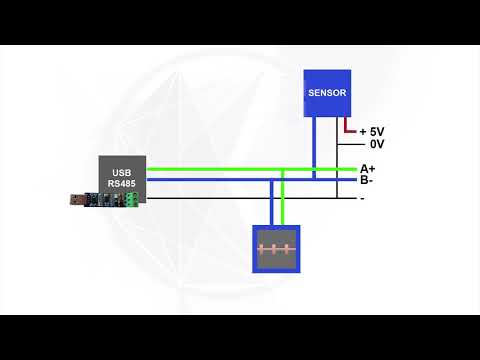

In [5]:
YouTubeVideo("mnRiYaYt2uI", width=700, height=394)


## 7. Décryptage : Du bus physique aux passerelles IP

### 7.1. L'exemple du capteur XY-MD02 vu dans la vidéo
Dans la vidéo, un capteur commercial de température et d'humidité **XY-MD02** est connecté au bus RS-485 :
- En consultant sa [fiche technique (documentation fabricant)](http://www.sahel.rs/media/sah/techdocs/xy-md02-manual.pdf) :
  - **Adresse esclave par défaut** : `0x01` (1).
  - **Registre 0x0001 (Input Register)** : Température (°C $\times$ 10). Une valeur lue de `215` correspond à **21.5 °C**.
  - **Registre 0x0002 (Input Register)** : Taux d'humidité relative (% $\times$ 10). Une valeur hexadécimale `0x01D0` (= 464 en décimal) correspond à **46.4 %**.
  - **Registre 0x0101 (Holding Register)** : Permet de reconfigurer l'adresse de l'esclave (de 1 à 247).

> 📌 **Leçon essentielle d'interopérabilité :**
> Modbus ne transporte que des suites d'octets et de mots de 16 bits. **Il ne comporte aucune métadonnée décrivant l'unité de mesure ou le format de codage**. Sans la documentation papier du fabricant, impossible de deviner que le registre `0x0002` contient un taux d'humidité et qu'il faut le diviser par 10 ! Nous verrons dans les semaines suivantes comment les protocoles IoT modernes résolvent ce problème.

---

### 7.2. Passerelle transparente vs Modbus TCP natif

Il existe deux manières courantes d'interconnecter un bus Modbus avec un réseau IP :

1. **La passerelle transparente (*Transparent TCP Gateway*)** :
   - La passerelle agit comme un simple pont réseau (tunnel TCP $\leftrightarrow$ RS-485).
   - On ouvre une socket TCP (généralement sur le port `502`) et on y envoie directement la trame Modbus RTU brute (avec son CRC).
   - C'est cette méthode qui est utilisée dans les scripts d'exploration du dossier `semaine_01/Modbus exploration/`.

2. **Le protocole Modbus TCP standard (MBAP)** :
   - La trame RTU est encapsulée avec un en-tête dédié de 7 octets appelé **MBAP** (*Modbus Application Protocol*) :
     - `Transaction Identifier` (2 octets) : identifiant de requête pour multiplexer les échanges.
     - `Protocol Identifier` (2 octets) : toujours `0x0000` pour Modbus.
     - `Length` (2 octets) : nombre d'octets restants.
     - `Unit Identifier` (1 octet) : l'adresse de l'esclave visé sur le bus série derrière la passerelle.
   - Le CRC-16 de fin est omis car TCP possède déjà sa propre somme de contrôle de niveau transport.


## 8. Les scripts d'exploration Modbus du projet

Dans le sous-dossier [`semaine_01/Modbus exploration/`](Modbus%20exploration/), 4 scripts Python sont fournis pour tester et explorer un vrai bus :
- [`scan_modbus.py`](Modbus%20exploration/scan_modbus.py) : scanne un port série USB (`/dev/cu.usbserial-...`) pour trouver les esclaves 1..247.
- [`scan_modbus_tcp.py`](Modbus%20exploration/scan_modbus_tcp.py) : scanne les esclaves 1..247 à travers une passerelle transparente TCP.
- [`list_registers.py`](Modbus%20exploration/list_registers.py) : découvre tous les registres lisibles d'un esclave série.
- [`list_registers_tcp.py`](Modbus%20exploration/list_registers_tcp.py) : découvre tous les registres lisibles d'un esclave via passerelle TCP.

Examinons comment fonctionne la fonction centrale de balayage issue de [`scan_modbus_tcp.py`](Modbus%20exploration/scan_modbus_tcp.py) :


In [6]:
import socket

def probe_slave_tcp(gateway_ip: str, port: int, slave_id: int, timeout: float = 0.5):
    """Interroge un esclave via une passerelle TCP transparente en lisant le registre 0 (fonction 0x03).
    Une réponse valide (même un code d'erreur 'illegal address') prouve la présence de l'esclave !
    """
    request = build_modbus_rtu_request(slave_address=slave_id, function_code=0x03, start_register=0, count=1)
    
    try:
        with socket.create_connection((gateway_ip, port), timeout=timeout) as sock:
            sock.sendall(request)
            answer = sock.recv(256)
            if len(answer) >= 5 and answer[0] == slave_id and crc16(answer) == 0:
                is_exception = bool(answer[1] & 0x80)
                return True, is_exception, answer
            return False, False, answer
    except (socket.timeout, ConnectionRefusedError, OSError):
        return False, False, b""

print("Fonction de scan prête. Elle sera utilisée avec notre simulateur ci-dessous !")


Fonction de scan prête. Elle sera utilisée avec notre simulateur ci-dessous !


## 9. Laboratoire Pratique : Simulateur et Client PyModbus

Pour vous permettre d'expérimenter immédiatement même sans passerelle matérielle branchée sur votre ordinateur, nous démarrons ici un **simulateur Modbus en arrière-plan** sur `127.0.0.1:5020`.

Ce simulateur reproduit :
1. **L'esclave 1 (Capteur météo XY-MD02)** :
   - Input Register `1` : Température actuelle (ex: 21.8 °C $\rightarrow$ 218)
   - Input Register `2` : Taux d'humidité actuel (ex: 46.2 % $\rightarrow$ 462)
2. **L'esclave 28 (Système de refroidissement de la centrale)** :
   - Input Register `0x00FF` (`255`) : Niveau d'eau du réacteur (en centièmes de pourcent, ex: `7540` = 75.40 %).
   - Holding Register `0x0200` (`512`) : Vitesse de la pompe de remplissage (0 = arrêt, 1500 = vitesse max).
   - Coil `1` : Voyant d'alarme niveau critique (True / False).


In [7]:
import threading
import time

class ModbusLocalSimulator:
    """Simulateur TCP local pour les TP Modbus."""
    def __init__(self, host="127.0.0.1", port=5020):
        self.host = host
        self.port = port
        self.running = False
        self.server_socket = None
        self.thread = None
        
        # État simulé des équipements
        self.temperature_x10 = 218      # 21.8 °C
        self.humidity_x10 = 462         # 46.2 %
        self.water_level_x100 = 7540    # 75.40 %
        self.pump_speed = 0             # 0 tr/min
        self.alarm_coil = False

    def handle_request(self, data: bytes) -> bytes:
        if len(data) < 8 or crc16(data) != 0:
            return b""  # Trame invalide ou mauvais CRC
            
        slave, func, reg, count_or_val = struct.unpack(">BBHH", data[:6])
        
        # --- Esclave 1 : Capteur XY-MD02 ---
        if slave == 1:
            if func == 0x04:  # Read Input Registers
                if reg == 1:   # Température
                    val = self.temperature_x10
                    resp = struct.pack(">BBB", slave, func, 2) + struct.pack(">H", val)
                    return resp + struct.pack("<H", crc16(resp))
                elif reg == 2: # Humidité
                    val = self.humidity_x10
                    resp = struct.pack(">BBB", slave, func, 2) + struct.pack(">H", val)
                    return resp + struct.pack("<H", crc16(resp))
            # Exception : registre inconnu
            resp = struct.pack(">BBB", slave, func | 0x80, 0x02)
            return resp + struct.pack("<H", crc16(resp))

        # --- Esclave 28 : Centrale Winden ---
        elif slave == 28:
            if func == 0x04 and reg == 0x00FF:  # Read Input Register : Niveau d'eau
                resp = struct.pack(">BBB", slave, func, 2) + struct.pack(">H", self.water_level_x100)
                return resp + struct.pack("<H", crc16(resp))
            elif func == 0x03 and reg == 0x0200: # Read Holding Register : Vitesse pompe
                resp = struct.pack(">BBB", slave, func, 2) + struct.pack(">H", self.pump_speed)
                return resp + struct.pack("<H", crc16(resp))
            elif func == 0x06 and reg == 0x0200: # Write Single Register : Vitesse pompe
                self.pump_speed = count_or_val
                resp = struct.pack(">BBHH", slave, func, reg, count_or_val)
                return resp + struct.pack("<H", crc16(resp))
            elif func == 0x01 and reg == 1:     # Read Coil : Alarme
                byte_val = 1 if self.alarm_coil else 0
                resp = struct.pack(">BBBB", slave, func, 1, byte_val)
                return resp + struct.pack("<H", crc16(resp))
            elif func == 0x05 and reg == 1:     # Write Coil : Alarme
                self.alarm_coil = (count_or_val == 0xFF00)
                resp = struct.pack(">BBHH", slave, func, reg, count_or_val)
                return resp + struct.pack("<H", crc16(resp))
            # Exception : registre inexistant
            resp = struct.pack(">BBB", slave, func | 0x80, 0x02)
            return resp + struct.pack("<H", crc16(resp))

        # Esclave non présent sur le bus : silence (aucune réponse)
        return b""

    def _run(self):
        self.server_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
        self.server_socket.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
        self.server_socket.bind((self.host, self.port))
        self.server_socket.listen(5)
        self.server_socket.settimeout(0.5)
        
        while self.running:
            try:
                conn, _ = self.server_socket.accept()
                with conn:
                    data = conn.recv(1024)
                    if data:
                        reply = self.handle_request(data)
                        if reply:
                            conn.sendall(reply)
            except (socket.timeout, OSError):
                continue

    def start(self):
        if not self.running:
            self.running = True
            self.thread = threading.Thread(target=self._run, daemon=True)
            self.thread.start()
            time.sleep(0.1)
            print(f"🚀 Simulateur Modbus démarré avec succès sur {self.host}:{self.port}")

    def stop(self):
        self.running = False
        if self.server_socket:
            try:
                self.server_socket.close()
            except Exception:
                pass
        print("🛑 Simulateur arrêté.")

# Instanciation et démarrage du simulateur
simulator = ModbusLocalSimulator(host="127.0.0.1", port=5020)
simulator.start()


🚀 Simulateur Modbus démarré avec succès sur 127.0.0.1:5020


### 9.1. Test du scanner d'esclaves sur notre passerelle simulée
Exécutons la recherche pour voir quels esclaves répondent sur le bus simulé :


In [8]:
print("Scan des esclaves 1 à 35 sur 127.0.0.1:5020...")
found = []
for slave_id in range(1, 35):
    ok, is_exc, answer = probe_slave_tcp("127.0.0.1", 5020, slave_id, timeout=0.2)
    if ok:
        status = "Réponse valide (Erreur Modbus)" if is_exc else "Réponse OK (Valeur lue)"
        print(f"  👉 Esclave détecté à l'adresse {slave_id:2d} ! ({status})")
        found.append(slave_id)

print(f"\nRésultat du scan : {len(found)} équipement(s) trouvé(s) -> {found}")


Scan des esclaves 1 à 35 sur 127.0.0.1:5020...
  👉 Esclave détecté à l'adresse  1 ! (Réponse valide (Erreur Modbus))
  👉 Esclave détecté à l'adresse 28 ! (Réponse valide (Erreur Modbus))

Résultat du scan : 2 équipement(s) trouvé(s) -> [1, 28]


### 9.2. Lecture et interprétation des données (Capteur XY-MD02)

Interrogeons l'esclave 1 (le capteur météo) pour lire les registres d'entrée 1 et 2 et appliquer le facteur d'échelle prescrit par le constructeur :


In [9]:
def read_input_register(slave_id: int, register_addr: int):
    req = build_modbus_rtu_request(slave_address=slave_id, function_code=0x04, start_register=register_addr, count=1)
    with socket.create_connection(("127.0.0.1", 5020), timeout=1.0) as sock:
        sock.sendall(req)
        resp = sock.recv(256)
    if len(resp) >= 7 and resp[0] == slave_id and crc16(resp) == 0:
        val = int.from_bytes(resp[3:5], "big")
        return val
    return None

temp_raw = read_input_register(slave_id=1, register_addr=1)
hum_raw = read_input_register(slave_id=1, register_addr=2)

print("--- Données brutes et converties du capteur XY-MD02 (Esclave 1) ---")
print(f"🌡️  Température lue : registre 1 = {temp_raw}  -->  {temp_raw / 10.0:.1f} °C")
print(f"💧  Humidité lue    : registre 2 = {hum_raw}  -->  {hum_raw / 10.0:.1f} %")


--- Données brutes et converties du capteur XY-MD02 (Esclave 1) ---
🌡️  Température lue : registre 1 = 218  -->  21.8 °C
💧  Humidité lue    : registre 2 = 462  -->  46.2 %


### 9.3. Mission : Réguler le niveau d'eau du réacteur (Esclave 28)

Interrogeons maintenant l'esclave 28 (la centrale de Winden) :
1. Lire le niveau d'eau actuel sur l'Input Register `0x00FF` (`255`).
2. Si le niveau est inférieur à 80 %, activer la pompe à eau en écrivant une vitesse de `1200` tr/min dans le Holding Register `0x0200` (`512`).
3. Vérifier que la consigne a bien été prise en compte !


In [10]:
def write_holding_register(slave_id: int, register_addr: int, value: int):
    req = struct.pack(">BBHH", slave_id, 0x06, register_addr, value)
    req += struct.pack("<H", crc16(req))
    with socket.create_connection(("127.0.0.1", 5020), timeout=1.0) as sock:
        sock.sendall(req)
        resp = sock.recv(256)
    return len(resp) >= 6 and crc16(resp) == 0

# 1. Lecture du niveau d'eau
level_raw = read_input_register(slave_id=28, register_addr=0x00FF)
level_percent = level_raw / 100.0
print(f"💧 Niveau d'eau actuel du réacteur : {level_raw} ({level_percent:.2f} %)")

# 2. Régulation : activer la pompe si < 80%
if level_percent < 80.0:
    print("⚠️  Niveau d'eau sous 80% ! Envoi de la commande de mise en route de la pompe...")
    success = write_holding_register(slave_id=28, register_addr=0x0200, value=1200)
    print(f"✅ Commande envoyée avec succès : {success}")
    print(f"   Vitesse actuelle de la pompe simulée : {simulator.pump_speed} tr/min")


💧 Niveau d'eau actuel du réacteur : 7540 (75.40 %)
⚠️  Niveau d'eau sous 80% ! Envoi de la commande de mise en route de la pompe...
✅ Commande envoyée avec succès : True
   Vitesse actuelle de la pompe simulée : 1200 tr/min


## 10. Quiz 2 : Modbus et programmation applicative

Vérifiez votre compréhension des aspects applicatifs et d'intégration de Modbus.


In [11]:
# Question 1:
display(Markdown("### Question 1\n**Pourquoi un scan Modbus considère-t-il une réponse d'exception (ex: 'Illegal Data Address') comme une preuve que l'esclave est présent ?**"))
q21_w = widgets.RadioButtons(options=[
    "Parce que le routeur réseau simule la réponse",
    "Parce que seul un équipement actif configuré avec cette adresse esclave peut générer une trame de refus avec son adresse et un CRC valide",
    "Parce que le protocole TCP garantit la livraison",
    "C'est une erreur, l'esclave n'est pas présent"
], layout=widgets.Layout(width="95%"))
q21_b = widgets.Button(description="Vérifier", button_style="primary")
q21_o = widgets.Output()

def check_q21(_):
    q21_o.clear_output()
    with q21_o:
        ok = q21_w.value.startswith("Parce que seul un équipement actif")
        display(_feedback(ok, "Sur un bus RS-485 partagé, si personne n'a cette adresse, rien n'est émis sur la ligne (timeout). Si une trame d'erreur signée avec cette adresse et un bon CRC revient, l'équipement est bien physiquement connecté !"))
q21_b.on_click(check_q21)
display(q21_w, q21_b, q21_o)

# Question 2:
display(Markdown("### Question 2\n**Quelle est la principale limite de Modbus en matière de sécurité pour l'Internet des Objets ?**"))
q22_w = widgets.RadioButtons(options=[
    "Il est limité à 247 équipements",
    "Il ne supporte pas les nombres flottants",
    "Les trames circulent en clair sans aucun chiffrement ni mécanisme d'authentification native",
    "Il nécessite obligatoirement un câble Ethernet"
], layout=widgets.Layout(width="95%"))
q22_b = widgets.Button(description="Vérifier", button_style="primary")
q22_o = widgets.Output()

def check_q22(_):
    q22_o.clear_output()
    with q22_o:
        ok = q22_w.value.startswith("Les trames circulent en clair")
        display(_feedback(ok, "Conçu en 1979 pour des réseaux d'usines fermés et isolés, Modbus ne dispose d'aucun mécanisme de sécurité natif (pas de mot de passe, pas de chiffrement, n'importe qui sur le réseau peut lire ou écraser les registres). C'est pourquoi son exposition directe sur Internet nécessite impérativement des passerelles sécurisées (VPN, TLS)."))
q22_b.on_click(check_q22)
display(q22_w, q22_b, q22_o)


### Question 1
**Pourquoi un scan Modbus considère-t-il une réponse d'exception (ex: 'Illegal Data Address') comme une preuve que l'esclave est présent ?**

RadioButtons(layout=Layout(width='95%'), options=('Parce que le routeur réseau simule la réponse', 'Parce que …

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

### Question 2
**Quelle est la principale limite de Modbus en matière de sécurité pour l'Internet des Objets ?**

RadioButtons(layout=Layout(width='95%'), options=('Il est limité à 247 équipements', 'Il ne supporte pas les n…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## 11. Bilan & Synthèse

| Caractéristique | Modbus (1979) | Ce que demande l'IoT moderne |
| :--- | :--- | :--- |
| **Topologie** | Maître / Esclaves (centralisé, pas de pair-à-pair) | Publish / Subscribe (MQTT) ou Client / Serveur REST (HTTP, CoAP) |
| **Sécurité** | Aucune (pas d'authentification, pas de chiffrement) | TLS / DTLS, jetons d'accès, chiffrement de bout en bout |
| **Modèle de données** | Registres numériques bruts (16 bits) sans type ni unité | Formats auto-descriptifs (JSON, CBOR, SenML) |
| **Consommation** | Nécessite d'interroger en permanence (*polling*) | Notifications push sur changement d'état ou événement |

Dans le prochain épisode, nous étudierons comment structurer et sérialiser les données de manière compacte et standardisée avec **CBOR** et **JSON** pour l'Internet des Objets !

---
*(Pour arrêter proprement le serveur simulateur local à la fin de votre session, vous pouvez exécuter la cellule suivante).*


In [12]:
simulator.stop()


🛑 Simulateur arrêté.
